# TimeDiff：PR10 尾部取樣與原 PR30 批次比較

## 結論
以原本的「組合報酬」取樣方法新增 **70% 完整母體＋30% PR10 以下**，共生成 2,000 條 21 日路徑。使用原模型，沒有重訓 TimeDiff 或 PPO，也沒有覆蓋原批次。

- 同一 PR10 門檻下，生成尾部占比由 17.0% 增至 **30.1%**；同一 PR30 門檻下由 45.35% 增至 **51.20%**。
- PR10 條件占比 36.4%，生成仍只有 30.1%；不是完全遵循條件。
- 生成股票相關性 0.218，仍低於配對真實 0.382；high／low 原始違規率為 20.73%／20.60%。
- 2,000 條收盤路徑皆不完全重複，涵蓋 397 個歷史視窗；不代表 2,000 個獨立風險事件。

這次證明此固定模型可以藉由 PR10 取樣增加深尾部路徑，尚未證明資料更真實或對 PPO 更有效。

## 方法與資料

兩組皆為 350 次完整母體抽樣＋150 次尾部抽樣，每次生成 4 條路徑。差別僅為尾部來源從組合 PR30 改成 PR10；不是三段混合，也不是隨機選單股。歷史 63 日、未來 21 日與組合報酬／年化波動條件成組保留。門檻只由 2010–2017 的 1,993 個訓練視窗計算。

同一 checkpoint、plan seed 20261017、diffusion seed 20261018、CPU、batch size 32、20 個生成步數。70% 完整來源的 1,400 條輸出逐位元一致，可將這批的差異定位到替換的尾部來源。

### 關鍵假設與限制
PR10 是 21 日每日等權再平衡組合報酬的訓練分位數，不是單日跌幅或個股分位數。完整來源仍含尾部；30% 尾部來源不等於整批只有 30% 尾部。重疊視窗及同條件複本相依；只有一個取樣與噪音種子，不提供 IID 信賴區間。所有路徑保留，未按生成結果篩選。

### 重現方式
從 TimeDiff 目錄執行 `.venv-spx/bin/python outputs/dow10/conditional/empirical_joint/run_20261017/analyses/pr30_vs_pr10/analyze.py` 重算完整比較。生成命令見同目錄 `generation_command_current.txt`，輸出目錄必須是新的。原始資料、模型、程式及產物 SHA-256 均保存在 `../../batches/full70_tail30_pr10/generation.json`，跨批次查核在 `comparison.json`。

## 資料讀取與查核

In [1]:
from pathlib import Path
import json
import io
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Image

ROOT=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'output_layout.py').is_file())
sys.path.insert(0,str(ROOT))
from output_layout import JOINT_RUN, PR10_BATCH, PR30_BATCH
HERE=JOINT_RUN/'analyses/pr30_vs_pr10'
assert (HERE/'comparison.json').exists(), '請從此 notebook 所在目錄或 TimeDiff 目錄執行'
sys.path.insert(0,str(HERE))
from analyze import structure
comparison=json.loads((HERE/'comparison.json').read_text())
tails=pd.read_csv(HERE/'tail_comparison.csv')
summaries=pd.read_csv(HERE/'summary_comparison.csv').set_index('batch')
cohorts=pd.read_csv(HERE/'cohort_comparison.csv')
coverage=pd.read_csv(HERE/'coverage_comparison.csv')
old=np.load(PR30_BATCH/'paths.npz',allow_pickle=False)
new=np.load(PR10_BATCH/'paths.npz',allow_pickle=False)
full=old['source_pool']=='full'
assert np.array_equal(old['raw_features'][full],new['raw_features'][full])
for label,z in [('PR30',old),('PR10',new)]:
    measured,_=structure(z['raw_features'])
    for threshold,cutoff in comparison['thresholds'].items():
        saved=tails[(tails.batch==label)&(tails.threshold==threshold)].iloc[0]
        assert int((measured.return_21d<=cutoff).sum())==saved.generated_count
        assert int((z['target'][:,0]<=cutoff).sum())==saved.target_count
        assert saved.target_count-saved.lost+saved.gained==saved.generated_count
plt.rcParams.update({'font.family':'Arial Unicode MS','font.size':11,
 'axes.unicode_minus':False,'axes.spines.top':False,'axes.spines.right':False})
BLUE,ORANGE,GRAY='#275c96','#b06b22','#969da5'
def show_plot(fig,name):
    fig.savefig(HERE/name,dpi=155)
    buffer=io.BytesIO()
    fig.savefig(buffer,format='png',dpi=155)
    display(Image(data=buffer.getvalue()))
    plt.close(fig)
print('原始陣列尾部計數、轉移帳與 1,400 條共同輸出一致性查核通過。')

原始陣列尾部計數、轉移帳與 1,400 條共同輸出一致性查核通過。


## 結果一：用相同門檻比較尾部與分布
每個占比的分母都是該批全部 2,000 條路徑。PR1、PR5、PR10、PR30 是巢狀事件，不可相加。條件占比與實際生成占比分開顯示。

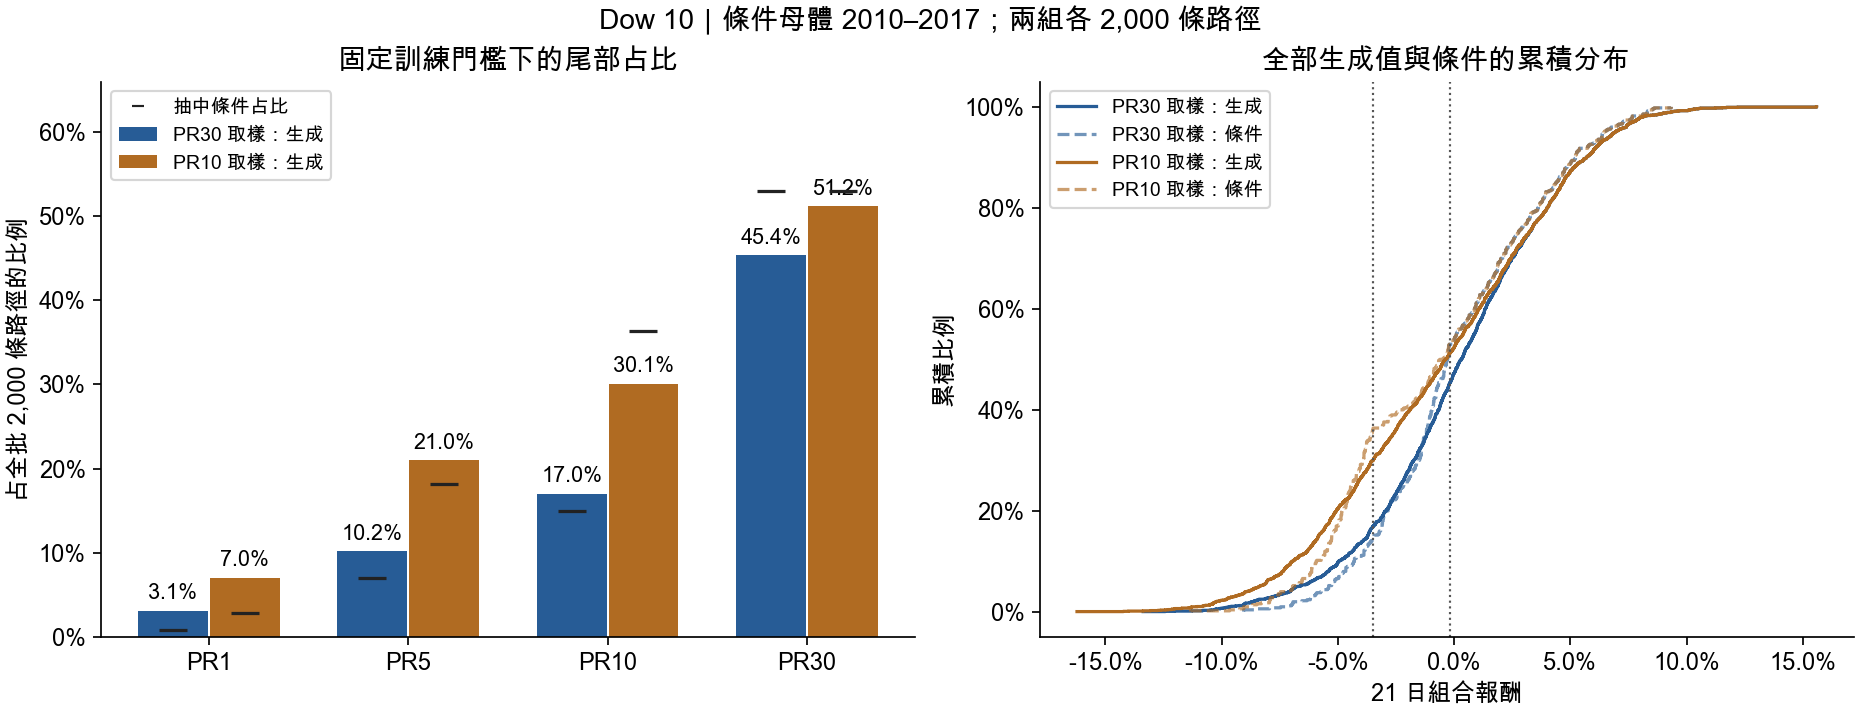

,batch,threshold,cutoff,expected_share,target_share,generated_share,lost,gained,retention
0,PR30,PR1,-0.0769,0.0171,0.008,0.0310,3,49,0.8125
1,PR30,PR5,-0.0491,0.0853,0.070,0.1020,39,103,0.7214
2,PR30,PR10,-0.0348,0.1706,0.150,0.1700,68,108,0.7733
3,PR30,PR30,-0.0018,0.5100,0.530,0.4535,240,87,0.7736
4,PR10,PR1,-0.0769,0.0370,0.028,0.0700,14,98,0.7500
5,PR10,PR5,-0.0491,0.1851,0.182,0.2100,93,149,0.7445
6,PR10,PR10,-0.0348,0.3702,0.364,0.3010,175,49,0.7596
7,PR10,PR30,-0.0018,0.5100,0.530,0.5120,123,87,0.8840


In [2]:
fig,axes=plt.subplots(1,2,figsize=(12,4.6),constrained_layout=True)
names=['PR1','PR5','PR10','PR30']
x=np.arange(4)
for offset,label,color in [(-.18,'PR30',BLUE),(.18,'PR10',ORANGE)]:
    t=tails[tails.batch==label].set_index('threshold').loc[names]
    bars=axes[0].bar(x+offset,t.generated_share,.35,color=color,label=f'{label} 取樣：生成')
    axes[0].scatter(x+offset,t.target_share,marker='_',s=180,color='#222222',zorder=5)
    axes[0].bar_label(bars,labels=[f'{v:.1%}' for v in t.generated_share],padding=3,fontsize=10)
axes[0].plot([],[],color='#222222',marker='_',ls='none',label='抽中條件占比')
axes[0].set_xticks(x,names)
axes[0].set(ylabel='占全批 2,000 條路徑的比例',ylim=(0,.66),title='固定訓練門檻下的尾部占比')
axes[0].yaxis.set_major_formatter(PercentFormatter(1));axes[0].legend(fontsize=9,loc='upper left')
for label,z,color in [('PR30',old,BLUE),('PR10',new,ORANGE)]:
    v=np.sort(z['realized'][:,0])
    axes[1].step(v,np.arange(1,len(v)+1)/len(v),where='post',color=color,label=f'{label} 取樣：生成')
    v=np.sort(z['target'][:,0])
    axes[1].step(v,np.arange(1,len(v)+1)/len(v),where='post',color=color,ls='--',alpha=.65,label=f'{label} 取樣：條件')
for k in ('PR10','PR30'):
    axes[1].axvline(comparison['thresholds'][k],color='#555555',ls=':',lw=1)
axes[1].set(xlabel='21 日組合報酬',ylabel='累積比例',title='全部生成值與條件的累積分布')
axes[1].xaxis.set_major_formatter(PercentFormatter(1));axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend(fontsize=9)
fig.suptitle('Dow 10｜條件母體 2010–2017；兩組各 2,000 條路徑',fontsize=13)
show_plot(fig,'tail_comparison.png')
display(tails[['batch','threshold','cutoff','expected_share','target_share','generated_share','lost','gained','retention']].round(4))

PR10 門檻為 **-3.4763%**。新批 PR10 目標 728 條，跨出 175 條、跨入 49 條，最後 602 條；目標尾部保留率 75.96%。

PR30 目標在兩批同為 53.0%，生成占比卻由 45.35% 提升至 51.20%，因為尾部來源移向更深的負報酬，較不容易跨回 PR30 以上。這不表示模型的條件誤差已被修復：報酬 MAE 由 1.578 增至 1.626 個百分點。

另需留意更深的尾部：新批 PR1 的條件占比只有 2.8%，生成卻有 7.0%，代表條件誤差也會把路徑推到更極端的跌幅；不能只看整體尾部變多就判定品質提升。

## 結果二：相關性與 high／low 修正
相關性為每條 21 日路徑內十檔股票的 45 對日 log return 相關係數平均，再對路徑取平均。high／low 違規率的分母各為每批 420,000 個股票交易日；這些原始違規值由既有價格重建 clipping 修正。

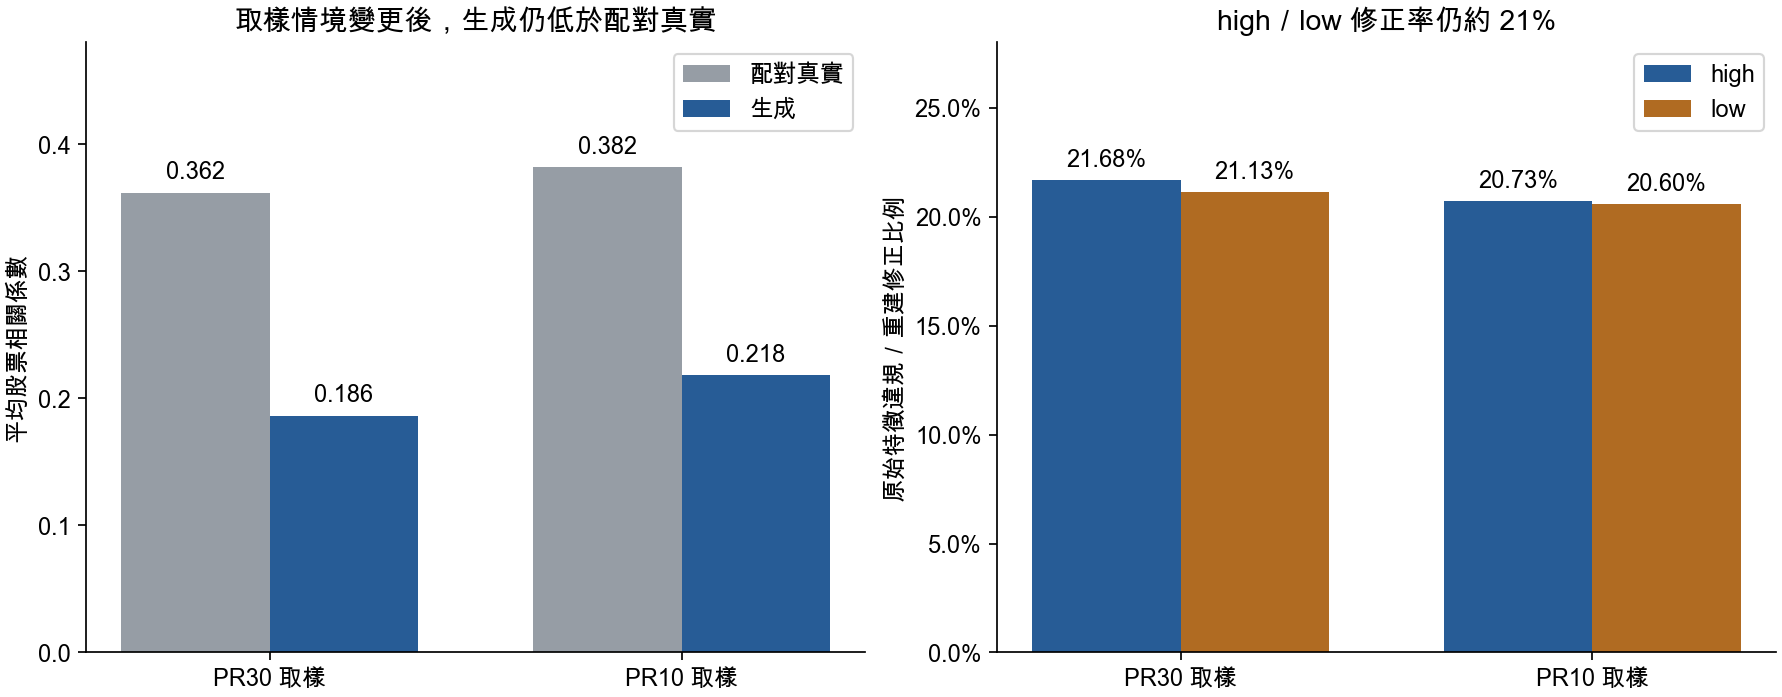

,batch,source,n_paths,generated_corr,paired_real_corr,return_mae,high_invalid,low_invalid
0,PR30,all,2000,0.1864,0.3618,0.0158,0.2168,0.2113
1,PR30,full,1400,0.1723,0.3394,0.0160,0.2243,0.2093
2,PR30,tail,600,0.2193,0.4142,0.0152,0.1994,0.2158
3,PR10,all,2000,0.2181,0.3819,0.0163,0.2073,0.2060
4,PR10,full,1400,0.1723,0.3394,0.0160,0.2243,0.2093
5,PR10,tail,600,0.3251,0.4810,0.0168,0.1675,0.1982


In [3]:
fig,axes=plt.subplots(1,2,figsize=(11.5,4.5),constrained_layout=True)
x=np.arange(2)
s=summaries.loc[['PR30','PR10']]
for shift,key,label,color in [(-.18,'paired_real_corr','配對真實',GRAY),(.18,'generated_corr','生成',BLUE)]:
    bars=axes[0].bar(x+shift,s[key],.36,label=label,color=color)
    axes[0].bar_label(bars,labels=[f'{v:.3f}' for v in s[key]],padding=4)
axes[0].set_xticks(x,['PR30 取樣','PR10 取樣'])
axes[0].set(ylabel='平均股票相關係數',ylim=(0,.48),title='取樣情境變更後，生成仍低於配對真實');axes[0].legend()
for shift,key,label,color in [(-.18,'high_invalid','high',BLUE),(.18,'low_invalid','low',ORANGE)]:
    bars=axes[1].bar(x+shift,s[key],.36,label=label,color=color)
    axes[1].bar_label(bars,labels=[f'{v:.2%}' for v in s[key]],padding=4)
axes[1].set_xticks(x,['PR30 取樣','PR10 取樣'])
axes[1].set(ylabel='原始特徵違規／重建修正比例',ylim=(0,.28),title='high／low 修正率仍約 21%')
axes[1].yaxis.set_major_formatter(PercentFormatter(1));axes[1].legend()
show_plot(fig,'structure_comparison.png')
pair=pd.read_csv(HERE/'pairwise_correlation.csv')
assert (pair.groupby('batch').gap.apply(lambda x:(x<0).sum())==45).all()
display(cohorts[['batch','source','n_paths','generated_corr','paired_real_corr','return_mae','high_invalid','low_invalid']].round(4))

PR10 批次的真實情境本身更相關：配對真實由 0.362 增至 0.382；生成由 0.186 增至 0.218。雖然差距略縮小，兩批的 45 對股票仍全部低於配對真實。個股殘餘變異仍為真實的 2.12 倍。

生成報酬的平均最大回撤由 -4.19% 變成 -4.99%，壓力程度提高。這是取樣情境變更的結果；模型與重建方法均未修改。

兩批的價格重建均沒有改變 PR1／PR5／PR10／PR30 的任何分類，差距不是價格重建造成的。

## 結果三：路徑多樣性與歷史覆蓋
固定同一歷史與報酬／波動條件下，仍由不同 diffusion noise 生成多條路徑。距離以 checkpoint 的訓練特徵尺度標準化；不是以本批波動重新縮放。

batch,PR30,PR10
n_unique_windows,415.0000,397.0000
diversity_n_unique_close_paths,2000.0000,2000.0000
diversity_mean_pairwise_normalized_rmse,1.4428,1.4479
diversity_median_pairwise_centered_rmse,1.4029,1.4085
diversity_median_pairwise_portfolio_return_correlation,0.4686,0.4923
diversity_original_future_copy_count_at_1e_minus_7,0.0000,0.0000


,batch,source,n_draws,n_unique_windows,max_repeats_same_window,largest_year_share,largest_year
0,PR30,all,500,415,4,0.166000,2015
1,PR30,full,350,314,3,0.154286,2015
2,PR30,tail,150,131,3,0.193333,2015
3,PR10,all,500,397,4,0.172000,2015
4,PR10,full,350,314,3,0.154286,2015
5,PR10,tail,150,99,4,0.213333,2015


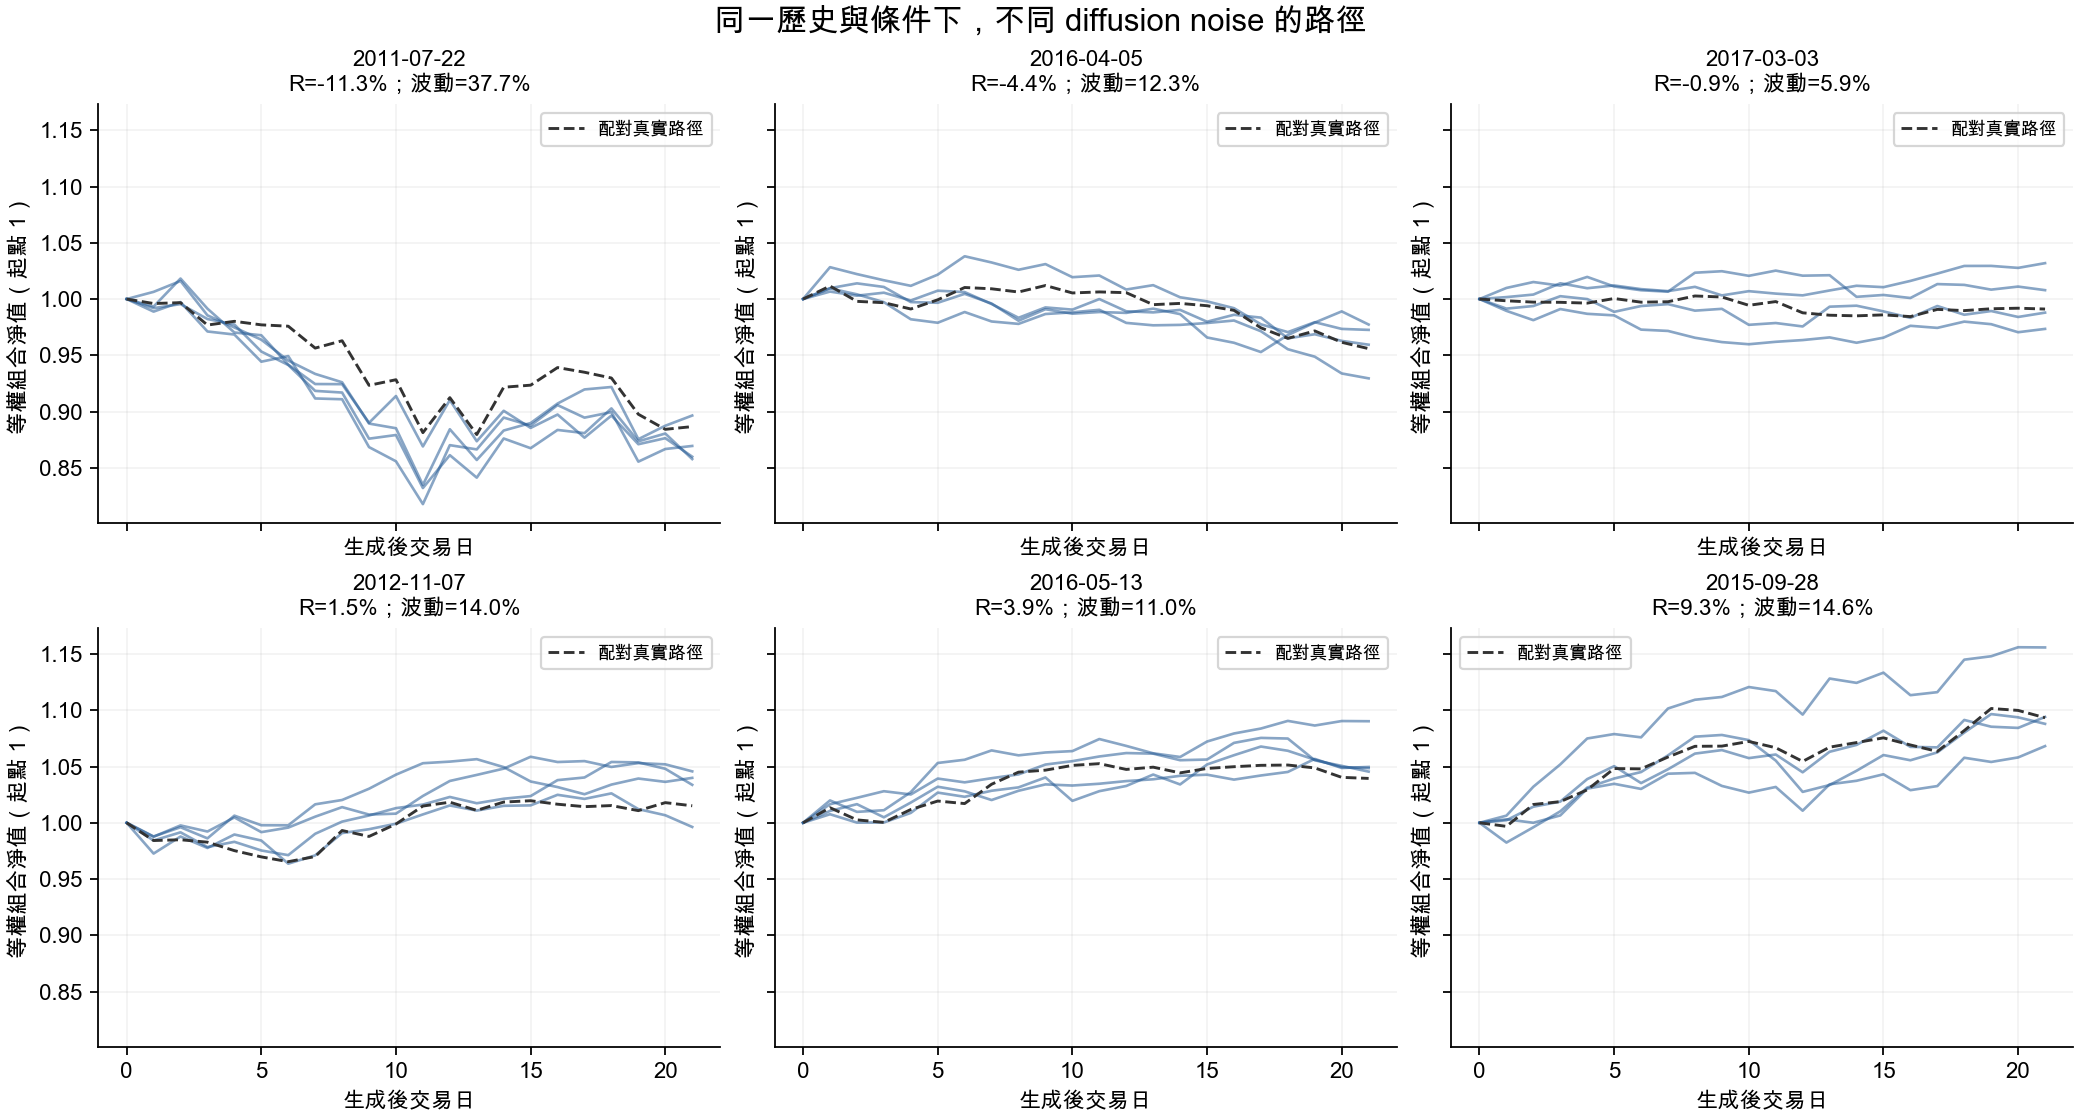

In [4]:
cols=['n_unique_windows','diversity_n_unique_close_paths','diversity_mean_pairwise_normalized_rmse',
      'diversity_median_pairwise_centered_rmse','diversity_median_pairwise_portfolio_return_correlation',
      'diversity_original_future_copy_count_at_1e_minus_7']
display(summaries[cols].T.round(4))
display(coverage)
# 已生成的固定條件示例：依目標報酬排名選六組，未依結果挑圖。
display(Image(filename=str(PR10_BATCH/'within_condition_paths.png')))

2,000 條路徑均不同，沒有同條件全部輸出完全相同的組別；也沒有與各自配對真實未來在 1e−7 容差內相同的收盤路徑。但這不是對全部訓練視窗的最近鄰查核，也不能單靠非重複性證明合理多樣性。

PR10 尾部母體由 PR30 的 598 個視窗縮至 200 個，150 次尾部抽樣中的不同視窗由 131 個降到 99 個。整批不同視窗由 415 降到 397；較深尾部增加的同時，歷史情境覆蓋較集中。

## 實驗判斷
本輪達成「增加深尾部資料」：可保留為後續研究的壓力情境批次。它沒有解決 high／low 支持範圍、個股殘餘變異或條件跨界問題；PR1 的過量生成也應納入品質指標。先保留這批與原 PR30 批次，後續若改善模型，使用共同 PR1／PR5／PR10／PR30 門檻與同樣的結構指標比較。沒有執行 PPO，也沒有依本輪結果調整模型或再抽樣。